In [1]:
import os
from pathlib import Path
import random
from typing import List, Tuple

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

import cv2
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# === CONFIG ===

# Path to your YOLO-style dataset for a given view
# (the dataset we already built: images/train, labels/train, images/val, labels/val)
DATASET_ROOT = Path(r"vetra_side_pose_dataset")  # change per view

IMAGES_TRAIN_DIR = DATASET_ROOT / "images" / "train"
IMAGES_VAL_DIR   = DATASET_ROOT / "images" / "val"
LABELS_TRAIN_DIR = DATASET_ROOT / "labels" / "train"
LABELS_VAL_DIR   = DATASET_ROOT / "labels" / "val"

# === KEYPOINT COUNT for this view ===
# side: 14, back: 10, udder-side: 5, etc.
NUM_KEYPOINTS = 14   # change for each view

# Training hyperparameters
IMG_SIZE = 640        # square size we resize to (like YOLO)
BATCH_SIZE = 16
NUM_EPOCHS = 80
LR = 1e-3
WEIGHT_DECAY = 1e-4
VAL_EVERY = 1

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)


Using device: cuda


In [15]:
class SingleCowKeypointDataset(Dataset):
    """
    Reads YOLO pose labels (one cow per image) and returns:
      image: tensor [3,H,W], normalized
      target: tensor [4 + 2*K] in normalized 0–1 coords
              [cx, cy, w, h, k1x, k1y, ..., kKx, kKy]
    """

    def __init__(self, img_dir: Path, lbl_dir: Path, img_size: int = 640, augment: bool = False,
                 num_keypoints: int = 14):
        self.img_dir = img_dir
        self.lbl_dir = lbl_dir
        self.img_size = img_size
        self.augment = augment
        self.num_keypoints = num_keypoints
        self.expected_len = 4 + 2 * num_keypoints

        exts = {".jpg", ".jpeg", ".png", ".bmp"}
        self.samples = []
        for img_path in sorted(img_dir.iterdir()):
            if img_path.suffix.lower() not in exts:
                continue
            lbl_path = lbl_dir / (img_path.stem + ".txt")
            if lbl_path.exists():
                self.samples.append((img_path, lbl_path))

        print(f"[{img_dir.name}] Found {len(self.samples)} images with labels")

        # Basic transforms
        t_list = [transforms.ToTensor(),
                  transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                       std=[0.229, 0.224, 0.225])]
        self.to_tensor = transforms.Compose(t_list)

    def __len__(self):
        return len(self.samples)

    def _load_label(self, lbl_path: Path) -> np.ndarray:
        with open(lbl_path, "r") as f:
            lines = [l.strip() for l in f.readlines() if l.strip()]
        if not lines:
            raise RuntimeError(f"Empty label file: {lbl_path}")
        line = lines[0]  # we assume one cow per image
        parts = line.split()
        if len(parts) < self.expected_len + 1:  # +1 for class id
            raise RuntimeError(
                f"Label {lbl_path} has {len(parts)-1} numeric values, "
                f"expected {self.expected_len} (4+2*K with K={self.num_keypoints}). "
                f"Line: '{line}'"
            )
        vals = np.array(list(map(float, parts[1:self.expected_len+1])), dtype=np.float32)
        return vals

    def __getitem__(self, idx):
        img_path, lbl_path = self.samples[idx]

        # Load image (with clear error if fails)
        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None:
            raise RuntimeError(f"Could not read image: {img_path}")

        img_bgr = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_bgr.shape[:2]

        # Letterbox to square
        scale = self.img_size / max(h, w)
        nh, nw = int(h * scale), int(w * scale)
        img_resized = cv2.resize(img_bgr, (nw, nh), interpolation=cv2.INTER_LINEAR)

        canvas = np.full((self.img_size, self.img_size, 3), 128, dtype=np.uint8)
        top = (self.img_size - nh) // 2
        left = (self.img_size - nw) // 2
        canvas[top:top+nh, left:left+nw] = img_resized

        img = canvas

        target = self._load_label(lbl_path)  # [4+2K]

        img_t = self.to_tensor(img)
        target_t = torch.from_numpy(target)

        return img_t, target_t


In [16]:
train_dataset = SingleCowKeypointDataset(IMAGES_TRAIN_DIR, LABELS_TRAIN_DIR, img_size=IMG_SIZE, augment=True)
val_dataset   = SingleCowKeypointDataset(IMAGES_VAL_DIR,   LABELS_VAL_DIR,   img_size=IMG_SIZE, augment=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)


[train] Found 403 images with labels
[val] Found 101 images with labels


In [17]:
class CowKeypointNet(nn.Module):
    def __init__(self, num_keypoints: int):
        super().__init__()
        self.num_keypoints = num_keypoints
        self.out_dim = 4 + 2 * num_keypoints

        # Pretrained MobileNetV3 backbone
        backbone = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
        self.features = backbone.features
        self.backbone_out_channels = backbone.classifier[0].in_features  # last conv channels

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(self.backbone_out_channels, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, self.out_dim),
            nn.Sigmoid(),   # outputs in [0,1] for all coords
        )

    def forward(self, x):
        x = self.features(x)      # [B,C,H',W']
        x = self.pool(x)          # [B,C,1,1]
        out = self.head(x)        # [B, 4+2K], normalized
        return out


In [18]:
model = CowKeypointNet(NUM_KEYPOINTS).to(DEVICE)

criterion = nn.SmoothL1Loss()   # L1-like, robust
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

print(model)


CowKeypointNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): SqueezeExcitation(
          (avgpool): AdaptiveAvgPool2d(output_size=1)
          (fc1): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
          (fc2): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
          (activation): ReLU()
          (scale_activation): Hardsigmoid()
        )
        (2): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1

In [19]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    for imgs, targets in loader:
        imgs = imgs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        preds = model(imgs)
        loss = criterion(preds, targets)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * imgs.size(0)

    return total_loss / len(loader.dataset)


@torch.no_grad()
def eval_one_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    for imgs, targets in loader:
        imgs = imgs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        preds = model(imgs)
        loss = criterion(preds, targets)
        total_loss += loss.item() * imgs.size(0)

    return total_loss / len(loader.dataset)


In [20]:
print("Train len:", len(train_dataset))
print("Val   len:", len(val_dataset))

for i in range(3):
    img, target = train_dataset[i]
    print(f"Sample {i}: img shape {img.shape}, target shape {target.shape}")


Train len: 403
Val   len: 101
Sample 0: img shape torch.Size([3, 640, 640]), target shape torch.Size([32])
Sample 1: img shape torch.Size([3, 640, 640]), target shape torch.Size([32])
Sample 2: img shape torch.Size([3, 640, 640]), target shape torch.Size([32])


In [21]:
best_val = float("inf")
best_path = DATASET_ROOT / f"cow_kpts_custom_{NUM_KEYPOINTS}k_best.pt"

for epoch in range(1, NUM_EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, DEVICE)
    val_loss = eval_one_epoch(model, val_loader, criterion, DEVICE)

    print(f"[Epoch {epoch:03d}] train_loss={train_loss:.5f}  val_loss={val_loss:.5f}")

    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), best_path)
        print(f"  🔥 New best val loss, model saved to {best_path}")


[Epoch 001] train_loss=0.00412  val_loss=0.00212
  🔥 New best val loss, model saved to vetra_side_pose_dataset\cow_kpts_custom_14k_best.pt
[Epoch 002] train_loss=0.00091  val_loss=0.00306
[Epoch 003] train_loss=0.00055  val_loss=0.00187
  🔥 New best val loss, model saved to vetra_side_pose_dataset\cow_kpts_custom_14k_best.pt
[Epoch 004] train_loss=0.00040  val_loss=0.00142
  🔥 New best val loss, model saved to vetra_side_pose_dataset\cow_kpts_custom_14k_best.pt
[Epoch 005] train_loss=0.00026  val_loss=0.00189
[Epoch 006] train_loss=0.00024  val_loss=0.00111
  🔥 New best val loss, model saved to vetra_side_pose_dataset\cow_kpts_custom_14k_best.pt
[Epoch 007] train_loss=0.00031  val_loss=0.00120
[Epoch 008] train_loss=0.00024  val_loss=0.00050
  🔥 New best val loss, model saved to vetra_side_pose_dataset\cow_kpts_custom_14k_best.pt
[Epoch 009] train_loss=0.00019  val_loss=0.00040
  🔥 New best val loss, model saved to vetra_side_pose_dataset\cow_kpts_custom_14k_best.pt
[Epoch 010] train_l

In [22]:
def predict_keypoints_on_image(img_path: Path, model, num_keypoints: int, img_size: int = 640):
    model.eval()
    bgr = cv2.imread(str(img_path))
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    h, w = rgb.shape[:2]

    # letterbox like dataset
    scale = img_size / max(h, w)
    nh, nw = int(h * scale), int(w * scale)
    img_resized = cv2.resize(rgb, (nw, nh), interpolation=cv2.INTER_LINEAR)
    canvas = np.full((img_size, img_size, 3), 128, dtype=np.uint8)
    top = (img_size - nh) // 2
    left = (img_size - nw) // 2
    canvas[top:top+nh, left:left+nw] = img_resized

    t_list = [
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225]),
    ]
    transform = transforms.Compose(t_list)

    inp = transform(canvas).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        out = model(inp)[0].cpu().numpy()  # [4+2K]

    bbox = out[0:4]              # (cx, cy, w, h) in 0–1
    kpts = out[4:]               # 2K
    kpts = kpts.reshape(num_keypoints, 2)  # (K,2) in 0–1 image coords

    # convert normalized coords → letterboxed image px
    # then invert letterbox to original image coords
    kpts_px = []
    for (nx, ny) in kpts:
        x_l = nx * img_size
        y_l = ny * img_size

        # remove letterbox offset and scale back
        x = (x_l - left) / scale
        y = (y_l - top) / scale
        kpts_px.append((x, y))
    kpts_px = np.array(kpts_px, dtype=np.float32)

    return rgb, kpts_px, bbox


In [23]:
def plot_custom_model_kpts(img_path: Path, model, num_keypoints: int,
                           keypoint_names: List[str], skeleton_edges: List[Tuple[int,int]],
                           figsize=(7,7)):
    img_rgb, kpts_px, bbox = predict_keypoints_on_image(img_path, model, num_keypoints)

    plt.figure(figsize=figsize)
    plt.imshow(img_rgb)
    plt.axis("off")

    # draw skeleton
    for i,j in skeleton_edges:
        x1, y1 = kpts_px[i]
        x2, y2 = kpts_px[j]
        if not (np.isnan(x1) or np.isnan(y1) or np.isnan(x2) or np.isnan(y2)):
            plt.plot([x1,x2],[y1,y2], linewidth=2)

    # draw points
    for idx, (x,y) in enumerate(kpts_px):
        if np.isnan(x) or np.isnan(y):
            continue
        plt.scatter(x, y, s=30)
        label = f"{idx}:{keypoint_names[idx]}"
        plt.text(x+3, y-3, label,
                 fontsize=7,
                 bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

    plt.title(img_path.name)
    plt.show()


In [25]:
# SIDE VIEW KEYPOINTS (14) – order must match your labels
KEYPOINT_NAMES = [
    "hoof_rear_left",          # 0
    "hoof_toe_tip_left",       # 1
    "hoof_heel_hairline_left", # 2
    "hock_left",               # 3
    "stifle_left",             # 4
    "hook_left",               # 5
    "pin_left",                # 6
    "spine_mid_hips",          # 7
    "spine_last_rib_top",      # 8
    "barrel_last_rib_bottom",  # 9
    "shoulder_point",          # 10
    "elbow_point",             # 11
    "loin_midpoint",           # 12
    "udder_floor_centre_rear"  # 13
]

name_to_idx = {n: i for i, n in enumerate(KEYPOINT_NAMES)}
name_to_idx


{'hoof_rear_left': 0,
 'hoof_toe_tip_left': 1,
 'hoof_heel_hairline_left': 2,
 'hock_left': 3,
 'stifle_left': 4,
 'hook_left': 5,
 'pin_left': 6,
 'spine_mid_hips': 7,
 'spine_last_rib_top': 8,
 'barrel_last_rib_bottom': 9,
 'shoulder_point': 10,
 'elbow_point': 11,
 'loin_midpoint': 12,
 'udder_floor_centre_rear': 13}

In [26]:
SKELETON_EDGES = [
    # Hind hoof + foot
    (name_to_idx["hoof_rear_left"], name_to_idx["hock_left"]),           # 0–3
    (name_to_idx["hoof_rear_left"], name_to_idx["hoof_toe_tip_left"]),   # 0–1
    (name_to_idx["hoof_rear_left"], name_to_idx["hoof_heel_hairline_left"]),  # 0–2

    # Hind leg to rump
    (name_to_idx["hock_left"], name_to_idx["stifle_left"]),              # 3–4
    (name_to_idx["stifle_left"], name_to_idx["pin_left"]),               # 4–6
    (name_to_idx["pin_left"], name_to_idx["hook_left"]),                 # 6–5
    (name_to_idx["hook_left"], name_to_idx["spine_mid_hips"]),           # 5–7

    # Topline
    (name_to_idx["spine_mid_hips"], name_to_idx["loin_midpoint"]),       # 7–12
    (name_to_idx["loin_midpoint"], name_to_idx["spine_last_rib_top"]),   # 12–8
    (name_to_idx["spine_last_rib_top"], name_to_idx["shoulder_point"]),  # 8–10

    # Body depth (NDDB body depth line)
    (name_to_idx["spine_last_rib_top"], name_to_idx["barrel_last_rib_bottom"]),  # 8–9

    # Udder depth path
    (name_to_idx["barrel_last_rib_bottom"], name_to_idx["udder_floor_centre_rear"]),  # 9–13
    (name_to_idx["hock_left"], name_to_idx["udder_floor_centre_rear"]),              # 3–13

    # Shoulder / heart-girth line (approx
    (name_to_idx["shoulder_point"], name_to_idx["elbow_point"]),         # 10–11
    (name_to_idx["spine_last_rib_top"], name_to_idx["elbow_point"]),     # 8–11  <-- heart-girth cross-section

    # Body length (NDDB body length line)
    (name_to_idx["shoulder_point"], name_to_idx["pin_left"]),            # 10–6
]


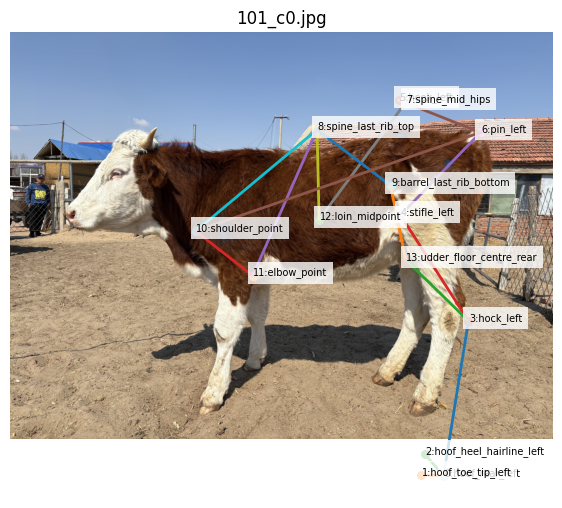

In [27]:
# define KEYPOINT_NAMES and SKELETON_EDGES for this view (we already did earlier)
# then:

sample_img = next(IMAGES_VAL_DIR.glob("*.jpg"))
plot_custom_model_kpts(sample_img, model, NUM_KEYPOINTS, KEYPOINT_NAMES, SKELETON_EDGES)
